In [1]:
from steane_ftec import *
import rotsurf_ftec as rsf
import bigsteane_ftec as bstf
import bigsteane as bst
import classes as c

import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Bitstream Vera Sans",
    "font.sans-serif": "Helvetica",
})

In [2]:
n = 1
avg = [0 for _ in range(7)]
for _ in range(n):
    y_list = avg7_ramsey("steane", 3, 0.00, qec = False, k = 1, bias = 0, post = True)         
    for index, j in enumerate(y_list):
        avg[index] += j 
avg = [i/n for i in avg]
print("\n", avg)
print(np.mean(avg))

Amount of gates in iteration 0:  17612  with depth  2411
Amount of gates in iteration 1:  8801  with depth  1212
Amount of gates in iteration 2:  4541  with depth  626
Performance for angle 1: 0.0 (62.79s) 

Amount of gates in iteration 0:  64  with depth  15
Amount of gates in iteration 1:  50  with depth  13
Amount of gates in iteration 2:  50  with depth  13
Performance for angle 3: 0.0 (0.01s) 

Amount of gates in iteration 0:  17550  with depth  2412
Amount of gates in iteration 1:  8895  with depth  1211
Amount of gates in iteration 2:  4615  with depth  627
Performance for angle 5: 0.0 (58.70s) 

Amount of gates in iteration 0:  48  with depth  13
Amount of gates in iteration 1:  42  with depth  11
Amount of gates in iteration 2:  39  with depth  11
Performance for angle 7: 0.0 (0.02s) 

Amount of gates in iteration 0:  17794  with depth  2411
Amount of gates in iteration 1:  8937  with depth  1210
Amount of gates in iteration 2:  4634  with depth  628
Performance for angle 9: 0

In [85]:
def u2(qc: QuantumCircuit, gate: list):
    for i in gate:
        if i == "S":
            qc.s(0)
        elif i == "T":
            qc.t(0)
        elif i == "H":
            qc.h(0)
        elif i == "Z":
            qc.z(0) 
        elif i == "X":
            qc.x(0)
        else:
            print("MISSING GATE: ", i)
            
def iQPE_ramsey(shots: int, p = 0):                 #das ist mit der decomp!
    angles = np.linspace(0,1,17)[1:16][1::2]
    p_x = p/2
    p_z = p/2
        
    p_error = pauli_error([["X",p_x],["I",1-p],["Z",p_z]])
    p_error_2 = pauli_error([["XI",p_x/2],["IX",p_x/2],["II",1-p],["ZI",p_z/2],["IZ",p_z/2]])
    p_error_3 = pauli_error([["XII",p_x/3],["IIX",p_x/3],["IXI",p_x/3],["III",1-p],["ZII",p_z/3],["IZI",p_z/3],["IIZ",p_z/3]])

    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(p_error, ['x', "z", 'h', "s", "sdg", "tdg", "t", "id"])  # Apply to single-qubit gates
    noise_model.add_all_qubit_quantum_error(p_error_2, ['cx'])  # Apply to 2-qubit gates
    noise_model.add_all_qubit_quantum_error(p_error_3, ['ccx'])  # Apply to 2-qubit gates

    y_list = [] ; gatecount = 0

    a = []
    with open("steane_u2_gridsynth_1e-2.txt", "r") as file:
        for line in file:
            a.append(list(map(str, line.strip().split(","))))

    qr = QuantumRegister(1,"q")
    cbits = ClassicalRegister(3*7,"c")
    qc = QuantumCircuit(qr, cbits)
    for o in range(7):
        for k in range(3):
            qc.h(0)
            for _ in range(2**(2-k)):
                u2(qc, a[2*o+1])
            if k == 1:
                with qc.if_test((0+3*o,1)):
                    qc.sdg(0)
            else:
                with qc.if_test((0+3*o,1)):
                    qc.tdg(0)
            with qc.if_test((1+3*o,1)):
                qc.sdg(0)
            qc.h(0)
            qc.id(0)
            qc.measure(0,k+3*o)
            qc.reset(0)
    gatecount += gates(qc)
    sim = AerSimulator()
    job = sim.run(qc, noise_model = noise_model, shots=shots)
    result = job.result()
    counts = result.get_counts()

    # print("Unoptimized circuit: ", dict(qc.count_ops()))
    # print("Transpiled circuit: ", dict(new_qc.count_ops()))

    for _, val in enumerate(list(counts.keys())):
        bruh = []           #temp list of the y_values aka the performance
        bitstring = val
        counter = counts[val]

        angles_measured = []
        for o in range(len(angles)):
            angles_measured.append(convert(bitstring[3*o:3*o+3]))

        angles_measured = angles_measured[::-1]
        for o in range(len(angles)):
            bruh.append(min(np.abs(angles_measured[o]-angles[o]), 1-np.abs(angles_measured[o]-angles[o])))

        for _ in range(counter):
            y_list.append(np.mean(bruh))
    
    y, err = np.mean(y_list), np.std(y_list)/np.sqrt(shots)
    
    return y, err, gatecount/(3*len(angles))



In [87]:
y, err, gatecount = iQPE_ramsey(1000, 0.9)

print("y: ", y)
print("err: ", err)
print("Gatecount (on avg. per iteration and angle): ", gatecount)

y:  0.2517142857142857
err:  0.0018657752669972811
Gatecount (on avg. per iteration and angle):  110.0


In [92]:
p = [10**(-i-1) for i in range(7)][1:]

y_list, err_list = [], []

for i in p:
    y, err, _ = iQPE_ramsey(1000, i)
    y_list.append(y), err_list.append(err)


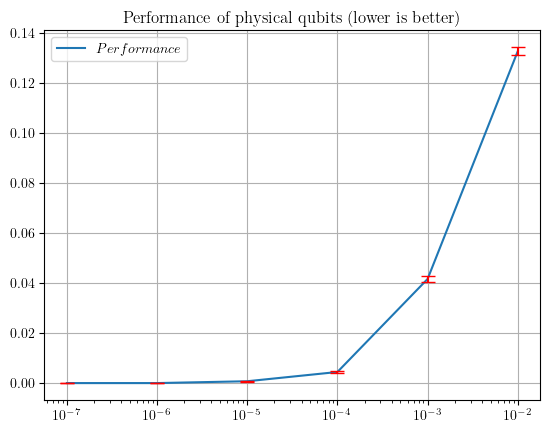

In [ ]:
plt.plot(p, y_list, label=r"$Performance$"), plt.errorbar(p, y_list, yerr=err_list, fmt='', capsize=5, color='red', linestyle='')
plt.title(r"Performance of physical qubits (lower is better)")
plt.grid()
# plt.yscale("log")
plt.xscale("log")
plt.legend()
plt.show()

# data = np.array((p, y_list, err_list))
# name = "physicalq_steane_crossover"
# np.savetxt("{}.txt".format(name), data, delimiter=",")

In [78]:
import random
angle = 0.5
distance = 0
for _ in range(10000):
    test = random.random()
    distance += min(np.abs(angle-test), 1-np.abs(angle-test))
distance /= 10000

print(distance)

0.25021693135947815
